# Coding Project 2: Credit Analytics

**Names of all group members:**


---

All code below is only suggestive and you may as well use different approaches.
Make sure that all requested quantities are printed or shown in tables/plots in the executed notebook.
A concise *Project Report* is required at the end of the notebook (see the last cells).

In [88]:
# Exercise 1.
import pandas as pd
import numpy as np
from tabulate import tabulate
np.random.seed(0)  # for reproducibility

# simulate explanatory variables x (the age and monthly income are assumed here to follow a continuous uniform distribution)
m = 20000
n = 10000
x_age = np.random.randint(low=18, high=80, size=m+n)
x_income = np.random.randint(low=1, high=15, size=m+n)
x_status = np.random.binomial(n=1, p=0.1, size=m+n)

# a) calculate and print the empirical means and standard deviations over the training data (i = 1, ..., m)
print(tabulate([
    ["Age", np.mean(x_age[:m]),  np.std(x_age[:m])],
    ["Monthly Income", np.mean(x_income[:m]),  np.std(x_income[:m])],
    ["Employment Status", np.mean(x_status[:m]),  np.std(x_status[:m])]
], headers=["Mean", "Standard Deviation"], tablefmt="outline"))

+-------------------+----------+----------------------+
|                   |     Mean |   Standard Deviation |
+===================+==========+======================+
| Age               | 48.5812  |            17.8656   |
| Monthly Income    |  7.53525 |             4.03853  |
| Employment Status |  0.0989  |             0.298528 |
+-------------------+----------+----------------------+


**1.b) Can you come up with a few (2 or 3) additional features that may be relevant?**

Some additional features that may be relevant could be:
1. How much unpaid debt the person currently has.
2. How many loans has the person taken out? How long did the person take until they paid their last loans back? (average weighted by recency)
3. How much can the person put up as collateral for the loan? (owned assets)

In [89]:
# Exercise 2.
# Building the datasets:

sigmoid = lambda x: 1. / (1. + np.exp(-x))
xi = np.random.uniform(low=0, high=1, size=m+n)

X_data = pd.DataFrame({
    "age": x_age,
    "monthly_income": x_income,
    "employment_status": x_status
})

X_train = X_data[:m]
X_test = X_data[m:]

# build the first dataset
p1 = 13.3 - 0.33*x_age + 3.5*x_income - 3*x_status
p1 = sigmoid(p1)

y1 = 1*(xi <= p1)

y1_train = y1[:m]
y1_test = y1[m:]


# build the second dataset
p2 = 5 - 10*((x_age<25)|(x_age>75)) + 1.1*x_income - x_status
p2 = sigmoid(p2)

y2 = 1*(xi <= p2)

y2_train = y2[:m]
y2_test = y2[m:]

In [90]:
# Exercise 2. a)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
# "model = LogisticRegression().fit(X_data, Y_data)" fits a model
# "pred_X = model.predict_proba(X)" evaluates the model
# (note that it outputs both P(Y=0|X) and P(Y=1|X))
# "log_loss(Y, pred_X)" evaluates the negative conditional log likelihood (also called cross-entropy loss)

# Fit the models on both datasets
model_p1 = LogisticRegression().fit(X_train, y1_train)
model_p2 = LogisticRegression().fit(X_train, y2_train)

y1_pred_log = model_p1.predict_proba(X_data)
y2_pred_log = model_p2.predict_proba(X_data)

# Calculate and print the cross-entropy loss on both datasets for train and test
print(tabulate([
    ["p_1", log_loss(y1_train, y1_pred_log[:m]),  log_loss(y1_test, y1_pred_log[m:])],
    ["p_2", log_loss(y2_train, y2_pred_log[:m]),  log_loss(y2_test, y2_pred_log[m:])]
], headers=["Training set", "Test set"], tablefmt="outline"))


+-----+----------------+------------+
|     |   Training set |   Test set |
+=====+================+============+
| p_1 |      0.0362883 |  0.0392772 |
| p_2 |      0.156247  |  0.153473  |
+-----+----------------+------------+


In [91]:
# Exercise 2. b)
# Calculate normalized data
# (as in the assignment: divide by the empirical standard deviations of the TRAINING data,
#  for both training and test data)
normalize = lambda x: x/np.std(x[:m])

X_normalized = X_data.copy()
X_normalized = X_normalized.apply(normalize)

In [92]:
# Exercise 2.b) (i) and (ii)
from sklearn.svm import SVC
# "model = SVC(kernel='rbf', gamma=GAMMA, C=C, probability=True)" creates
# a model with kernel exp(-GAMMA \|x-x'\|_2^2) and regularization parameter C (note the relation between C and the parameter lambda from the lecture).
# "probability=True" enables the option "model.predict_proba(X)" to predict probabilities from the regression function \hat{f}^{svm}.
# "model.fit(X, Y)" optimizes the model parameters (using hinge loss)
svc_p1 = SVC(kernel='rbf', gamma=0.1, C=0.2, probability=True).fit(X_normalized[:m], y1_train)
svc_p2 = SVC(kernel='rbf', gamma=0.1, C=0.2, probability=True).fit(X_normalized[:m], y2_train)

# Fit the models for both datasets (this can take up to 60 seconds with SVC)
# Note: "model.fit(...)" modifies the model object in place, so use a separate model object
# for each dataset if you want to keep both fitted models.

c:\Users\karim\Documents\ETH_Projects\mlfi_projects_hs26\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\karim\Documents\ETH_Projects\mlfi_projects_hs26\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [93]:
# Exercise 2.b (iii)
# "model.predict_proba(X)" predicts probabilities from features (note that it outputs both P(Y=0|X) and P(Y=1|X))

y1_pred_svc = svc_p1.predict_proba(X_normalized)
y2_pred_svc = svc_p2.predict_proba(X_normalized)

# Calculate and print the cross-entropy loss on both normalized datasets for train and test
print(tabulate([
    ["p_1", log_loss(y1_train, y1_pred_svc[:m]),  log_loss(y1_test, y1_pred_svc[m:])],
    ["p_2", log_loss(y2_train, y2_pred_svc[:m]),  log_loss(y2_test, y2_pred_svc[m:])]
], headers=["Training set", "Test set"], tablefmt="outline"))

+-----+----------------+------------+
|     |   Training set |   Test set |
+=====+================+============+
| p_1 |      0.0382261 |  0.0408363 |
| p_2 |      0.065116  |  0.0662867 |
+-----+----------------+------------+


**2.b (iv) Would the results change using standardized data instead of normalized data? No need to run any code here, only explain your reasoning.**

The results would not change since we are using an isotropic kernel. That is, if $\mu$ is the true mean of the data, then
$$
\begin{align*}
    k(x, x') &= k\left( \| x - x' \|_2^2 \right)\\
             &= k\left( \| (\tilde x + \mu) - (\tilde x' + \mu) \|_2^2 \right)\\
             &= k\left( \| \tilde x - \tilde x' \|_2^2 \right)\\
\end{align*}
$$
where $\tilde x, \tilde x'$ are centered random variables.

Dataset 1 with logistic regression: 0.0002772406110242053
Dataset 2 with logistic regression: 0.008706051894526754
Dataset 1 with SVC: 0.00029717003114364797
Dataset 2 with SVC: 0.0007953092361037071


C:\Users\karim\AppData\Local\Temp\ipykernel_20568\2837083447.py:54: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


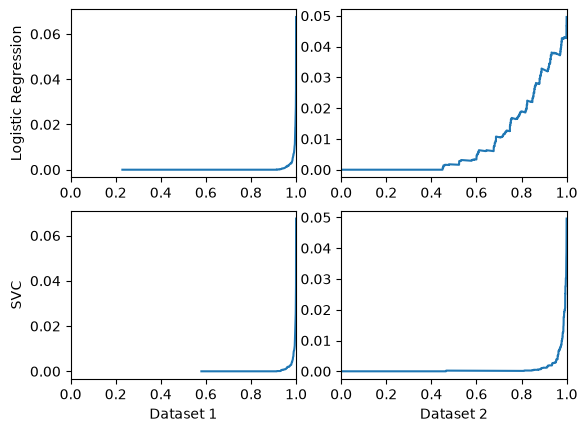

In [121]:
# Exercise 2.c
import matplotlib.pyplot as plt
# Plot the FDR/TPR-curves with the TPR on the horizontal axis and the FDR on the vertical axis,
# and compute the AUC of each plotted curve on the test data.
# Thresholds c: you may use all distinct predicted probabilities (this gives the exact curve), or a grid of
# values in [0, 1]. A uniform grid such as np.linspace(0, 1, 100) can be too coarse when many predicted
# probabilities are very close to 1. Check that your curve covers TPR values from (close to) 0 to 1.

# To approximately calculate the AUC, it is fine to simply use Riemann sums.
# This means, if you have N (a_i, b_i) pairs for the curves, ordered such that a_1 <= a_2 <= ... <= a_N,
# then you may simply use the sum
# sum_{i=1}^{N-1} (b_i + b_{i+1})/2 * (a_{i+1}-a_i)
# as the approximation of the integral (or AUC)

def compute_fdr_tpr(y_true, y_pred, ax):
    a = np.sort(y_pred[m:, 1]) 


    n_tp = np.array([np.count_nonzero(y_true[m:]*(c <= y_pred[m:,1])) for c in a])
    n_fp = np.array([np.count_nonzero((1-y_true[m:])*(c <= y_pred[m:,1])) for c in a])
    n_fn = np.array([np.count_nonzero(y_true[m:]*(c > y_pred[m:,1])) for c in a])

    # Calculate FDR and TPR rate (points on the FDR/TPR curve) and the AUC
    fdr = n_fp/(n_fp + n_tp)
    tpr = n_tp/(n_tp + n_fn)

    ax.plot(tpr, fdr)
    ax.set_xlim([0,1])

    auc = np.sum((fdr[:n-1]+fdr[1:])/2 * (tpr[:n-1]-tpr[1:]))

    return auc
    

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2)
ax1.set_ylabel("Logistic Regression")
ax3.set_ylabel("SVC")
ax3.set_xlabel("Dataset 1")
ax4.set_xlabel("Dataset 2")

# first data set & logistic regression:
# (the code should be reusable for all cases, only exchanging datasets and predicted probabilities depending on the model)
print(f'Dataset 1 with logistic regression: {compute_fdr_tpr(y1, y1_pred_log, ax1)}')

# second data set & logistic regression:
print(f'Dataset 2 with logistic regression: {compute_fdr_tpr(y2, y2_pred_log, ax2)}')

# first data set and SVM:
print(f'Dataset 1 with SVC: {compute_fdr_tpr(y1, y1_pred_svc, ax3)}')

# second data set and SVM:
print(f'Dataset 2 with SVC: {compute_fdr_tpr(y2, y2_pred_svc, ax4)}')

fig.show()

# Print the AUC values.
# Briefly explain (in a Markdown cell or comments) how you construct the curves, interpret what
# the AUC means in this setting, and compare the two models on both data sets.

I create four numpy arrays, each threshold the number of true positives, true negatives, false positives and false negatives are computed. This is simply done using list comprehension. The thresholds to check for have been selected by simply going through a sorted array of all prediction probabilties for the test set.

The True Positive Rate (TPR) is, as the name suggests, the proportion of true positives against total positives, so in other words
$$\text{TPR} = \frac{\text{TP}}{\text{TP $+$ FN}}$$

The False Discovery Rate (FPR) is the proportion of false negatives against the predicted positives, so
$$\text{FPR} = \frac{\text{FP}}{\text{FP $+$ TP}}$$

The AUC determines how accurate a model is, taking into account selectivity and sensitivity of the model at any threshold. An AUC very close to 0 means that at nearly any threshold the model can accurately identify good borrowers without mistakenly flagging deliquent borrowers as good borrowers.

I would choose Logistic Regression for the first dataset, as it has a marginally smaller AUC than SVC. This is not a very meaningful difference however. On Dataset 2, SVC seems to be the better choice over Logistic Regression based on AUC values. We remark as well that Logistic regression has larger FDR values for lower TPR values starting at 0.4. That means we start identifying more delinquent borrowers as good in exchange for getting more good borrowers (more false discoveries in exchange for more true positives)

In [122]:
# Exercise 3.

# Set model parameters and define matrix D
# (D has n x 50000 = 5*10^8 entries: a float64 array of uniforms of this size needs about 4 GB of memory.
#  If your machine runs out of memory, consider generating D in blocks of columns and/or storing it as booleans.)
D = np.random.uniform(low=0, high=1, size=(n, 50000))

for i, x in enumerate(p2[m:]):
    D[i, :] = D[i, :] <= x

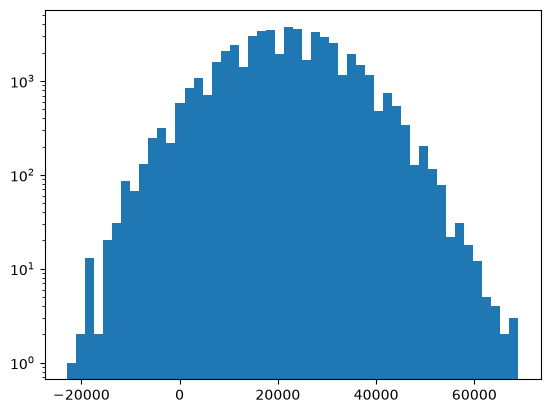

Expected P&L: 21625.9958
95%-VaR: -2455.0


In [123]:
# Strategy (i):
# Define Portfolio and possible outcomes for this portfolio using matrix D
strategy_1 = 1055*D
strategy_1 = np.sum(strategy_1, axis=0)
strategy_1-= n*1000

# Plot histogram of profits and losses
plt.hist(strategy_1,log=True,bins=50)
plt.show()

# Calculate expected profit and losses and 95%-VaR
print(f'Expected P&L: {np.mean(strategy_1)}')
print(f'95%-VaR: {-np.quantile(strategy_1, q=0.05)}')

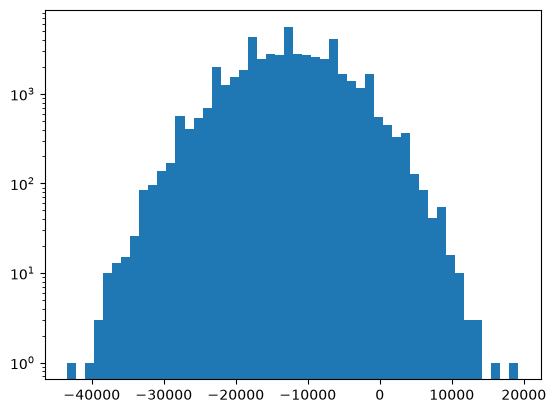

Expected P&L: -12484.405
95%-VaR: 24210.0


In [124]:
# Strategy (ii):
# Define Portfolio and possible outcomes using the matrix D and the predicted repayment probabilities from the logistic regression model
lending_log = y2_pred_log[m:,1] >=0.95
strategy_2 = 1010*D
strategy_2 = strategy_2.T @ lending_log
strategy_2-= np.count_nonzero(lending_log)*1000

# Plot histogram of profits and losses
plt.hist(strategy_2,log=True,bins=50)
plt.show()

# Calculate expected profit and losses and 95%-VaR
print(f'Expected P&L: {np.mean(strategy_2)}')
print(f'95%-VaR: {-np.quantile(strategy_2, q=0.05)}')

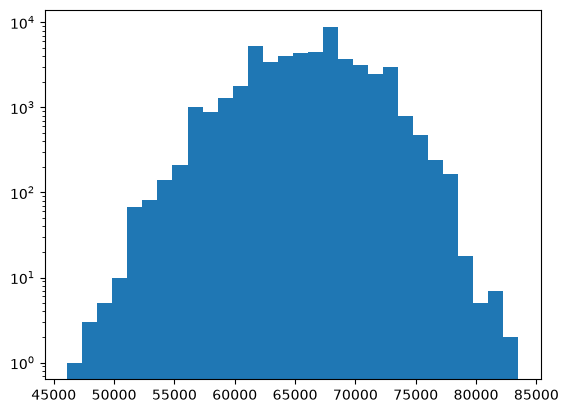

Expected P&L: 66223.8682
95%-VaR: -59250.0


In [125]:
# Strategy (iii):
# Define Portfolio and possible outcomes using the matrix D and the predicted repayment probabilities from the SVM model
# (evaluated on the normalized test features x~_i, see the assignment)
lending_svc = y2_pred_svc[m:,1] >=0.95
strategy_3 = 1010*D
strategy_3 = strategy_3.T @ lending_svc
strategy_3-= np.count_nonzero(lending_svc)*1000


# Plot histogram of profits & losses (which is simply the performance of each strategy in scenario k, i.e. a profit if positive or a loss if negative)
plt.hist(strategy_3,log=True,bins=30)
plt.show()

# Calculate and print the expected profit & loss and 95%-VaR for each strategy (in CHF)
print(f'Expected P&L: {np.mean(strategy_3)}')
print(f'95%-VaR: {-np.quantile(strategy_3, q=0.05)}')

**c) Compare the three strategies and briefly interpret your results (Markdown cell or comments).**

The basic strategy of just lending everyone 1000 CHF with 5.5% interest is a profitable one, even in the 5%-worst scenario. However we can read off the histogram that there are still a sizeable chunk of scenarios which result in a loss.

The strategy based on SVC probability predictions is by far more profitable. The logistic regression probability predictions even resulting in negative expected value. The histogram tells us that there are a negligeable amount of scenarios where we lose money lending according to strategy 3. This lines up with the models' performance wrt log-loss and AUC.

## Project Report

#### Approach
I simulate 30,000 borrowers using age, monthly income and employment status, with 20,000 observations for training and 10,000 for testing. Two sigmoid functions define artificial ground-truth repayment probabilities: the first uses a linear combination of the features, while the second includes an age penalty for borrowers younger than 25 or older than 75. Repayment outcomes are sampled from these probabilities.

I fit logistic regression and an RBF-kernel SVC using the given hyperparameters. The SVC uses normalized features, divided by their training-set standard deviations for both fitting and prediction. I evaluate probability predictions using log-loss and using test-set FDR/TPR curves and their AUC. For dataset 2, I simulate 50,000 repayment scenarios and compare three strategies on the same scenarios: lending CHF 1,000 to everyone at 5.5% interest, or lending at 1% only when the logistic regression or SVC repayment prediction is at least 0.95. I summarize performance by mean P&L and 95%-VaR.

#### Model selection
For dataset 1, I would choose logistic regression. Its test log-loss is slightly lower than the SVC's (0.03928 versus 0.04084), and its FDR/TPR area is also marginally smaller. These small differences do not represent a meaningful advantage. For lending on dataset 2, I would choose the SVC: its test log-loss is substantially lower (0.06629 versus 0.15347), its FDR/TPR area is much smaller, and its strategy has a higher mean P&L and a lower 95%-VaR than logistic regression selection. The nonlinear kernel can represent the age penalties more flexibly.

Because lending uses probability thresholds, accurate probability estimates matter beyond ranking borrowers correctly. I therefore consider log-loss, the FDR/TPR curves and portfolio performance together. The curve area summarizes the tradeoff across thresholds; lower area is better because fewer defaults are accepted at a given fraction of repaying borrowers approved. Neither overall log-loss nor curve area alone establishes performance at the prescribed lending cutoff.

#### Key results
The latest saved model results are:

| Dataset | Model | Training log-loss | Test log-loss | Test FDR/TPR area |
| --- | --- | ---: | ---: | ---: |
| 1 | Logistic regression | 0.03629 | 0.03928 | 0.000277 |
| 1 | SVC | 0.03823 | 0.04084 | 0.000297 |
| 2 | Logistic regression | 0.15625 | 0.15347 | 0.008706 |
| 2 | SVC | 0.06512 | 0.06629 | 0.000795 |

For the 50,000 simulated portfolio scenarios on dataset 2:

| Strategy | Mean P&L (CHF) | 95%-VaR (CHF) |
| --- | ---: | ---: |
| (i) Lend to everyone at 5.5% | 21,626.00 | -2,455.00 |
| (ii) Logistic regression selection at 1% | -12,484.41 | 24,210.00 |
| (iii) SVC selection at 1% | 66,223.87 | -59,250.00 |

#### Interpretation
The results show why lending decisions depend on both repayment probabilities and interest rates. With no recovery after default, a CHF 1,000 loan at 1% interest has expected P&L of $1010p-1000$, where $p$ is its true repayment probability. It breaks even only at $p=1000/1010 \approx 0.9901$. Therefore, the prescribed prediction cutoff of 0.95 can admit loans with negative expected profit even if the predictions are accurate. At a true repayment probability of 0.95, the expected loss is CHF 40.50 per loan.

SVC selection produces the strongest portfolio results in this run, while logistic regression selection loses money on average. This is consistent with the SVC capturing the nonlinear repayment structure more effectively. Lending to everyone remains profitable on average because the higher 5.5% interest rate compensates for more defaults.

#### Robustness
The results depend on the sampled borrower features, repayment labels, SVC probability estimation and simulated portfolio outcomes. The fixed random seed supports reproducibility when the notebook is run in order, but does not establish robustness across samples. Similar training and test losses provide some reassurance about generalization within this simulated setting; the small model difference on dataset 1 could change with another sample.

Using 50,000 scenarios reduces Monte Carlo noise, and sharing scenarios across strategies makes their comparison more precise. However, additional scenarios do not remove uncertainty in the fitted models or the underlying assumptions. Exact profits, VaR values and the strategy ranking may change with another sample, while the economic break-even condition remains unchanged.

#### Limitations
The data are synthetic and contain only three features, sampled without the relationships present in real borrower populations. Repayments are independent across borrowers conditional on their features, so the simulation excludes shared economic shocks and correlated defaults. The model also assumes full repayment with interest or total loss of principal, with no recovery, funding costs, collateral, operating costs, taxes or timing differences.

The comparison uses a single train/test split and does not directly assess probability calibration near the lending cutoff. The curve areas are numerical approximations over the TPR range reached by the observed probability thresholds; tied maximum predictions can limit coverage near zero TPR. 95%-VaR describes a percentile and does not measure the severity of losses beyond it. 95%-ES could provide a more trustworthy image of the risk.